## Évaluation des modèles retenus

Ce notebook relève de la phase Evaluation de CRISP-DM. Les modèles retenus dans `10_modeling.ipynb`, dont la configuration a été figée et versionnée avant toute évaluation, sont entraînés une fois sur tout le développement, puis évalués sur les trois ensembles de test du protocole et sur la validation externe `cropcut`. La référence hiérarchique est entraînée sur le même développement.

**Règles appliquées**

- Les ensembles de test sont évalués une seule fois, et leurs résultats ne modifient aucun choix de modélisation.
- Les scores sont ventilés par partition, pays, culture, niveau administratif et source, et ceux de `survey` sont rapportés avec et sans les surfaces GPS recopiées.
- Un modèle n'est retenu que s'il bat la référence en validation croisée et sur les ensembles de test.

**Préalable**

Les modèles et leurs prédictions sont produits par `python -m src.models.evaluation_finale`, en deux minutes environ. Le notebook relit ces prédictions et s'exécute en moins d'une minute.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))

from src.data.load import DOSSIER_TRAITE
from src.models.evaluation_finale import TESTS, VALIDATION_EXTERNE, charger_modele, scores, ventilation
from src.models.experiences import DOSSIER_MODELES, charger_table
from src.models.selection import courbes_retenues

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 100)
evaluations = {jeu: pd.read_csv(DOSSIER_MODELES / f"{jeu}_evaluation.csv.gz", low_memory=False) for jeu in ["regional", "survey"]}
PAYS = {"regional": "country", "survey": "Country"}

### 1. Tests unitaires

In [2]:
execution = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-t", "."],
    cwd=RACINE, capture_output=True, text=True,
)
print(execution.stderr.strip().splitlines()[-3:])

['Ran 95 tests in 0.957s', '', 'OK']


### 2. Scores sur les ensembles de test

La compétence est la part de l'erreur `mae_log` de la référence supprimée par le modèle. La moyenne par pays donne à chaque pays le même poids.

In [3]:
for jeu, evaluation in evaluations.items():
    partitions = TESTS + ([VALIDATION_EXTERNE] if jeu == "survey" else [])
    print(jeu)
    display(scores(evaluation, PAYS[jeu], partitions).round(3))

regional


,lignes,mae_log,mae_log_reference,competence,mae_log_macro_pays,mae_log_macro_pays_reference,biais_log,biais_log_reference,r2,mae_t_ha,erreur_relative_typique
test_temporel,13221.0,0.310,0.398,0.223,0.329,0.432,-0.013,-0.086,0.771,0.914,0.363
test_spatial,22843.0,0.321,0.389,0.174,0.341,0.394,0.011,-0.005,0.063,1.151,0.378
test_spatio_temporel,3108.0,0.334,0.404,0.172,0.396,0.495,-0.028,-0.112,0.762,1.120,0.397


survey


,lignes,mae_log,mae_log_reference,competence,mae_log_macro_pays,mae_log_macro_pays_reference,biais_log,biais_log_reference,r2,mae_t_ha,erreur_relative_typique
test_temporel,39093.0,0.765,0.828,0.076,0.769,0.815,0.050,-0.236,0.235,1.077,1.150
test_spatial,20503.0,0.716,0.756,0.053,0.712,0.779,-0.022,0.013,0.215,1.049,1.047
test_spatio_temporel,9249.0,0.767,0.822,0.068,0.756,0.817,0.149,-0.158,0.267,1.167,1.152
cropcut_grappes_tenues_a_l_ecart,2297.0,0.669,0.676,0.011,0.669,0.676,0.333,0.252,-0.068,0.648,0.952


**Constat**

- Dans `regional`, le modèle atteint 0,310 sur le test temporel, 0,321 sur le test spatial et 0,334 sur le test spatio-temporel, contre 0,398, 0,389 et 0,404 pour la référence. Sa compétence vaut 22,3 %, 17,4 % et 17,2 %, et sa moyenne par pays progresse autant.
- Le biais logarithmique de la référence sur les années futures, de -0,086 et -0,112, tombe à -0,013 et -0,028.
- Dans `survey`, le modèle atteint 0,765, 0,716 et 0,767, contre 0,828, 0,756 et 0,822, soit une compétence de 7,6 %, 5,3 % et 6,8 %. Le biais de la référence sur la dernière vague, de -0,236, devient 0,050.
- Sur les mesures de `cropcut` des grappes tenues à l'écart, le modèle atteint 0,669 contre 0,676, soit 1,1 % de compétence, avec un biais de 0,333.
- Le coefficient de détermination en tonnes par hectare ne vaut que 0,063 sur le test spatial de `regional`, alors qu'il dépasse 0,76 sur les deux autres tests.

**Analyse**

- Les deux modèles satisfont la règle de retenue du protocole. Ils battent la référence en validation croisée et sur chacun des ensembles de test.
- L'intégration de l'année, du climat et de la position corrige le retard de la référence sur la tendance des rendements, que le protocole avait relevé.
- Le faible coefficient de détermination du test spatial provient de quinze rendements de tabac aberrants, examinés à la section 7.

### 3. Cohérence avec la validation interne

Les scores de test sont comparés aux scores de la validation interne correspondante, obtenus au nombre d'arbres retenu.

In [4]:
for jeu in evaluations:
    table = charger_table(jeu)
    developpement = table[table["partition"] == "developpement"]
    courbes = courbes_retenues(jeu, developpement)
    attendu = courbes.loc[courbes["moyenne"].idxmin(), ["croisee", "temporelle", "spatio_temporelle"]]
    observe = scores(evaluations[jeu], PAYS[jeu], TESTS)["mae_log"]
    ordre = ["test_spatial", "test_temporel", "test_spatio_temporel"]
    display(pd.DataFrame({"validation interne": attendu.to_numpy(), "test": observe.reindex(ordre).to_numpy()},
                         index=["spatial", "temporel", "spatio-temporel"]).round(3).rename_axis(jeu))

,validation interne,test
regional,,
spatial,0.358,0.321
temporel,0.372,0.310
spatio-temporel,0.428,0.334


,validation interne,test
survey,,
spatial,0.719,0.716
temporel,0.757,0.765
spatio-temporel,0.758,0.767


**Constat**

- Dans `survey`, les scores de test s'écartent de moins de 0,01 des scores internes, de 0,719 à 0,716 pour le spatial, de 0,757 à 0,765 pour le temporel et de 0,758 à 0,767 pour le spatio-temporel.
- Dans `regional`, les scores de test sont meilleurs que les scores internes, de 0,358 à 0,321 pour le spatial, de 0,372 à 0,310 pour le temporel et de 0,428 à 0,334 pour le spatio-temporel.

**Analyse**

- Pour `survey`, la validation interne prédisait fidèlement la performance, ce qui confirme qu'elle ne surestimait pas le modèle.
- Pour `regional`, le modèle final apprend sur toutes les années du développement, alors que la validation temporelle interne s'arrêtait à 2011. Les années futures de `regional` proviennent aussi à 82 % de `HarvestStat`, plus homogène que les autres sources. La référence progresse d'ailleurs dans la même proportion, de 0,432 à 0,398 sur le temporel. Les ensembles de test étant indépendants de la sélection, cet écart ne traduit pas une fuite.

### 4. Ventilations de regional

Les erreurs sont ventilées par source, par niveau administratif, par pays et par culture.

In [5]:
regional = evaluations["regional"]
for cle in ["Source", "level"]:
    display(ventilation(regional, cle).round(3))
pays = ventilation(regional, "country").reset_index()
pays = pays[pays["lignes"] >= 200]
print("Part des pays d'au moins 200 lignes où le modèle bat la référence :",
      pays.groupby("partition")["competence"].apply(lambda c: round((c > 0).mean(), 2)).to_dict())
display(pays[pays["competence"] < 0].round(3))
cultures = ventilation(regional, "crop").reset_index()
display(cultures[cultures["lignes"] >= 200].pivot(index="crop", columns="partition", values="competence").round(3))

lignes  mae_log  mae_log_reference  biais_log  competence
partition            Source                                                                    
test_spatial         AgroMAPS           1797    0.295              0.345      0.028       0.146
                     FAO_subnational     914    0.343              0.458     -0.008       0.252
                     HarvestStat       17319    0.318              0.387      0.016       0.177
                     RCeA               2813    0.347              0.404     -0.023       0.141
test_spatio_temporel FAO_subnational     153    0.316              0.419     -0.070       0.246
                     HarvestStat        2558    0.313              0.376     -0.052       0.168
                     RCeA                397    0.478              0.575      0.146       0.168
test_temporel        FAO_subnational     665    0.255              0.356     -0.010       0.285
                     HarvestStat       10834    0.299              0.384     -0.034       0.222
                     RCeA               1722    0.397              0.502      0.121       0.209

lignes  mae_log  mae_log_reference  biais_log  competence
partition            level                                                           
test_spatial         1       10780    0.340              0.424      0.009       0.198
                     2       12063    0.304              0.357      0.014       0.149
test_spatio_temporel 1        1429    0.352              0.446     -0.056       0.210
                     2        1679    0.319              0.368     -0.004       0.133
test_temporel        1        5385    0.309              0.414     -0.038       0.253
                     2        7836    0.310              0.388      0.004       0.200

Part des pays d'au moins 200 lignes où le modèle bat la référence : {'test_spatial': 0.9, 'test_spatio_temporel': 1.0, 'test_temporel': 0.92}


,partition,country,lignes,mae_log,mae_log_reference,biais_log,competence
20,test_spatial,Madagascar,657,0.300,0.289,-0.005,-0.040
32,test_spatial,South Africa,381,0.347,0.346,0.005,-0.003
67,test_temporel,Mozambique,473,0.511,0.470,-0.212,-0.087


partition,test_spatial,test_spatio_temporel,test_temporel
crop,,,
Banana,0.009,NaN,NaN
Beans,0.105,NaN,0.135
Cassava,0.300,0.279,0.327
Cotton,0.155,NaN,0.076
Cowpea,0.205,0.087,0.263
Groundnut,0.317,0.230,0.271
Maize,0.214,0.256,0.232
Millet,0.267,NaN,0.152
Okra,-0.140,NaN,0.114


**Constat**

- Le modèle bat la référence pour chaque source et chaque niveau administratif de chaque ensemble de test, avec une compétence comprise entre 13,3 et 28,5 %.
- Parmi les pays d'au moins 200 lignes, il bat la référence dans 90 % des pays du test spatial, 92 % du test temporel et 100 % du test spatio-temporel. Il fait moins bien à Madagascar et en Afrique du Sud sur le test spatial, de 4,0 et 0,3 %, et au Mozambique sur le test temporel, de 8,7 %, avec un biais de -0,212.
- Parmi les cultures, la compétence atteint 21 à 33 % pour le maïs, le manioc et l'arachide. Elle est négative pour le gombo et le pois d'Angole sur le test spatial.

**Analyse**

Le gain est général. Les exceptions concernent des pays et des cultures peu représentés dans le développement, et la sous-estimation du Mozambique sur les années futures suggère une hausse des rendements récents que ni la tendance ni le climat n'anticipent.

### 5. Ventilations de survey

Le protocole impose de rapporter les scores de `survey` avec et sans les parcelles dont la surface GPS recopie exactement la surface déclarée.

In [6]:
survey = evaluations["survey"]
recopiee = survey["flag_surface_gps_recopiee"].astype("boolean").fillna(False).astype(bool)
for nom, masque in [("toutes les parcelles", np.ones(len(survey), bool)), ("sans surfaces GPS recopiées", ~recopiee)]:
    print(nom)
    display(scores(survey[masque], "Country", TESTS)[["lignes", "mae_log", "mae_log_reference", "competence", "biais_log"]].round(3))
pays = ventilation(survey[survey["partition"].isin(TESTS)], "Country").reset_index()
display(pays.pivot(index="Country", columns="partition", values="competence").round(3))

toutes les parcelles


,lignes,mae_log,mae_log_reference,competence,biais_log
test_temporel,39093.0,0.765,0.828,0.076,0.050
test_spatial,20503.0,0.716,0.756,0.053,-0.022
test_spatio_temporel,9249.0,0.767,0.822,0.068,0.149


sans surfaces GPS recopiées


,lignes,mae_log,mae_log_reference,competence,biais_log
test_temporel,35065.0,0.766,0.835,0.083,0.010
test_spatial,19996.0,0.717,0.756,0.052,-0.020
test_spatio_temporel,8401.0,0.765,0.826,0.075,0.124


partition,test_spatial,test_spatio_temporel,test_temporel
Country,,,
Benin,0.397,NaN,NaN
Côte dIvoire,0.095,NaN,NaN
Ethiopia,0.058,0.087,0.090
Guinea-Bissau,-0.186,NaN,NaN
Malawi,0.042,0.131,0.118
Mali,0.188,0.123,-0.020
Niger,0.073,0.033,0.115
Nigeria,-0.007,0.060,-0.013
Senegal,0.081,0.145,0.103


**Constat**

- Sans les surfaces recopiées, les erreurs restent à 0,766, 0,717 et 0,765, et la compétence à 8,3 %, 5,2 % et 7,5 %. Le biais du test temporel passe de 0,050 à 0,010.
- Le modèle bat la référence dans la plupart des pays. Il fait moins bien en Guinée-Bissau et au Nigeria sur le test spatial, de 18,6 et 0,7 %, au Mali et au Nigeria sur le test temporel, de 2,0 et 1,3 %, et au Togo sur le test spatio-temporel, de 3,7 %.

**Analyse**

- Les surfaces recopiées ne modifient pas les conclusions.
- Le modèle de `survey` reste modeste, conformément à l'hétérogénéité des parcelles voisines et au bruit des rendements déclarés, que les variables disponibles ne décrivent pas.

### 6. Validation externe sur cropcut

Le modèle de `survey` prédit le rendement déclaré par l'enquête. Il est confronté aux rendements mesurés par coupe, dont seules les 2 297 mesures des grappes tenues à l'écart sont indépendantes de l'entraînement.

In [7]:
cropcut = survey[survey["partition"].str.startswith("cropcut")]
display(scores(cropcut, "Country", [VALIDATION_EXTERNE, "cropcut_grappes_vues"]).round(3))
cultures = ventilation(cropcut[cropcut["partition"] == VALIDATION_EXTERNE], "Crop").reset_index()
display(cultures[cultures["lignes"] >= 50].round(3))

,lignes,mae_log,mae_log_reference,competence,mae_log_macro_pays,mae_log_macro_pays_reference,biais_log,biais_log_reference,r2,mae_t_ha,erreur_relative_typique
cropcut_grappes_tenues_a_l_ecart,2297.0,0.669,0.676,0.011,0.669,0.676,0.333,0.252,-0.068,0.648,0.952
cropcut_grappes_vues,8966.0,0.655,0.698,0.062,0.655,0.698,0.277,0.188,0.035,0.677,0.925


,partition,Crop,lignes,mae_log,mae_log_reference,biais_log,competence
0,cropcut_grappes_tenues_a_l_ecart,Barley,190,0.693,0.694,0.556,0.002
1,cropcut_grappes_tenues_a_l_ecart,Beans,351,0.690,0.747,0.342,0.076
2,cropcut_grappes_tenues_a_l_ecart,Groundnut,59,0.833,1.040,0.439,0.199
3,cropcut_grappes_tenues_a_l_ecart,Maize,479,0.690,0.692,0.360,0.002
4,cropcut_grappes_tenues_a_l_ecart,Millet,127,0.597,0.711,0.126,0.160
6,cropcut_grappes_tenues_a_l_ecart,Sesame,98,0.614,0.667,0.094,0.079
7,cropcut_grappes_tenues_a_l_ecart,Sorghum,388,0.672,0.592,0.333,-0.134
10,cropcut_grappes_tenues_a_l_ecart,Teff,339,0.639,0.636,0.243,-0.005
11,cropcut_grappes_tenues_a_l_ecart,Wheat,228,0.643,0.637,0.453,-0.010


**Constat**

- Sur les grappes tenues à l'écart, le modèle atteint 0,669 contre 0,676 pour la référence, et son biais logarithmique vaut 0,333 contre 0,252.
- Sur les grappes déjà vues, il atteint 0,655 contre 0,698, soit 6,2 % de compétence.
- La compétence est positive pour le millet, l'arachide, les haricots et le sésame, et négative pour le sorgho, à -13,4 %.

**Analyse**

- Le modèle reproduit le biais des enquêtes, dont les rendements déclarés dépassent les mesures par coupe d'environ 40 % pour ses prédictions. Ce biais ne peut être corrigé sans validation spécifique, conformément au protocole.
- Le faible gain sur cropcut montre que le modèle prédit mal la variation propre aux mesures par coupe, et qu'il ne remplace pas une mesure directe.

### 7. Rendements aberrants de regional

Le faible coefficient de détermination en tonnes par hectare du test spatial conduit à examiner les rendements extrêmes. Le rapport de chaque rendement retenu à la médiane de sa culture est calculé sur `regional_prepare`.

In [8]:
prepare = pd.read_csv(DOSSIER_TRAITE / "regional_prepare.csv.gz", low_memory=False)
mediane = prepare[prepare["yieldTonHa"] > 0].groupby("crop")["yieldTonHa"].median()
modelisation = charger_table("regional")
rapport = modelisation["yieldTonHa"] / modelisation["crop"].map(mediane)
for seuil in [100, 10]:
    suspects = modelisation[rapport > seuil]
    print(f"Lignes retenues dont le rendement dépasse {seuil} fois la médiane de leur culture :", len(suspects))
    display(suspects.groupby(["crop", "country", "Source"]).agg(
        lignes=("yieldTonHa", "size"), minimum=("yieldTonHa", "min"), maximum=("yieldTonHa", "max"),
        premiere=("harvest_year", "min"), derniere=("harvest_year", "max")).round(2))
bornes = pd.read_csv(DOSSIER_TRAITE / "bornes_plausibilite.csv.gz", index_col=0)
print("Borne haute du tabac selon le filtre des auteurs :", round(bornes.loc["Tobacco", "borne_haute"], 1), "t/ha")
erreurs_unite = regional["yieldTonHa"] / regional["crop"].map(mediane) > 100
print("Lignes de test concernées par une erreur d'unité :", regional.loc[erreurs_unite, "partition"].value_counts().to_dict())
display(scores(regional[~erreurs_unite], "country", TESTS)[["lignes", "mae_log", "mae_log_reference", "competence", "r2", "mae_t_ha"]].round(3))

Lignes retenues dont le rendement dépasse 100 fois la médiane de leur culture : 15


,,,lignes,minimum,maximum,premiere,derniere
crop,country,Source,,,,,
Tobacco,Malawi,RCeA,15,610.19,1471.0,2016,2016


Lignes retenues dont le rendement dépasse 10 fois la médiane de leur culture : 314


lignes  minimum  maximum  premiere  derniere
crop       country                          Source                                                       
Banana     Angola                           HarvestStat           1    44.41    44.41      2012      2012
           Burundi                          HarvestStat           3    39.90    41.62      2013      2015
           Cameroon                         AgroMAPS              3    42.80    49.44      1989      2001
           Democratic Republic of the Congo HarvestStat           2    54.59    54.59      2015      2015
           Egypt                            AgroMAPS              5    37.00    51.36      2001      2001
           Kenya                            HarvestStat           3    38.72    50.59      2011      2012
           Malawi                           HarvestStat           2    38.38    48.32      2005      2005
           Mozambique                       HarvestStat           2    40.00    54.98      2020      2020
           Uganda                           HarvestStat           1    47.24    47.24      2008      2008
Beans      Uganda                           HarvestStat           1     8.18     8.18      2008      2008
Cowpea     Benin                            HarvestStat           2     5.06     6.81      1998      1998
           Burkina Faso                     AgroMAPS              2    10.69    10.73      1993      1997
                                            FAO_subnational     192     5.00    15.98      1995      2018
                                            HarvestStat           3     5.12     6.22      1995      2022
           Burundi                          HarvestStat           2     6.12    11.36      2012      2012
           Nigeria                          HarvestStat           3     5.13     9.30      2007      2012
           Uganda                           AgroMAPS              1     5.32     5.32      1991      1991
           Zambia                           HarvestStat           1     6.02     6.02      2016      2016
Groundnut  Burkina Faso                     FAO_subnational       2     7.80     7.88      2009      2011
           Democratic Republic of the Congo AgroMAPS              2     8.27     8.67      1995      1996
           Gambia                           AgroMAPS              1    10.26    10.26      2000      2000
           Madagascar                       HarvestStat           1     9.43     9.43      2005      2005
           Uganda                           HarvestStat           1     8.42     8.42      2008      2008
Sesame     Burkina Faso                     FAO_subnational      10     4.94    12.69      2008      2012
           Malawi                           HarvestStat           1     5.00     5.00      2009      2009
           Uganda                           HarvestStat           1     5.44     5.44      2009      2009
Sugar beet Egypt                            AgroMAPS             16    37.06    75.84      2001      2001
           Morocco                          AgroMAPS              9    33.63    68.10      1996      1999
Tobacco    Malawi                           RCeA                 15   610.19  1471.00      2016      2016
           Niger                            HarvestStat          26    12.00    28.95      2012      2018

Borne haute du tabac selon le filtre des auteurs : 1532.0 t/ha
Lignes de test concernées par une erreur d'unité : {'test_spatial': 6}


,lignes,mae_log,mae_log_reference,competence,r2,mae_t_ha
test_temporel,13221.0,0.310,0.398,0.223,0.771,0.914
test_spatial,22837.0,0.319,0.387,0.175,0.814,0.899
test_spatio_temporel,3108.0,0.334,0.404,0.172,0.762,1.120


**Constat**

- Quinze lignes dépassent 100 fois la médiane de leur culture, de 610 à 1 471 t/ha. Ce sont toutes des lignes de tabac du Malawi, issues de `RCeA` pour la récolte de 2016. Six d'entre elles appartiennent au test spatial.
- La borne haute de plausibilité du tabac, calculée selon le filtre des auteurs à deux fois le 98e percentile, vaut 1 532 t/ha. Le filtre ne protège qu'une culture dont moins de 2 % des valeurs sont corrompues.
- Sans ces six lignes, le coefficient de détermination du test spatial passe de 0,063 à 0,814, et l'erreur `mae_log` de 0,321 à 0,319.
- 314 lignes dépassent 10 fois la médiane de leur culture. Celles de banane et de betterave sucrière restent plausibles. Le niébé et le sésame de `FAO_subnational` au Burkina Faso, de 5 à 16 t/ha, et le tabac de `HarvestStat` au Niger, de 12 à 29 t/ha, dépassent en revanche les rendements connus de ces cultures.

**Analyse**

- Un rapport de 600 à 1 400 à la médiane signale une production exprimée en kilogrammes au lieu de tonnes. Le modèle prédit pour ces lignes un rendement d'environ 1 t/ha, plausible, et seule l'évaluation en est affectée.
- Les autres cas suspects ne peuvent être tranchés sans référentiel agronomique des rendements maximaux.
- L'anomalie a été découverte sur les ensembles de test. La corriger dans la préparation demanderait de relancer la modélisation et l'évaluation, ce qui relève d'une décision du porteur du projet.

**Conséquences pour la suite**

Les scores principaux sont rapportés sans retrait, et les scores sans les quinze erreurs d'unité sont rapportés en complément. La correction est proposée comme amélioration de la préparation.

### 8. Importance des variables

L'importance d'une variable est sa part du gain total des divisions des arbres du modèle final.

regional : part du gain des familles de variables
{'climat': np.float64(0.205), 'sols': np.float64(0.15), 'relief': np.float64(0.034), 'calendrier': np.float64(0.009), 'autres': np.float64(0.602)}
survey : part du gain des familles de variables
{'climat': np.float64(0.0), 'sols': np.float64(0.165), 'relief': np.float64(0.065), 'calendrier': np.float64(0.02), 'autres': np.float64(0.75)}


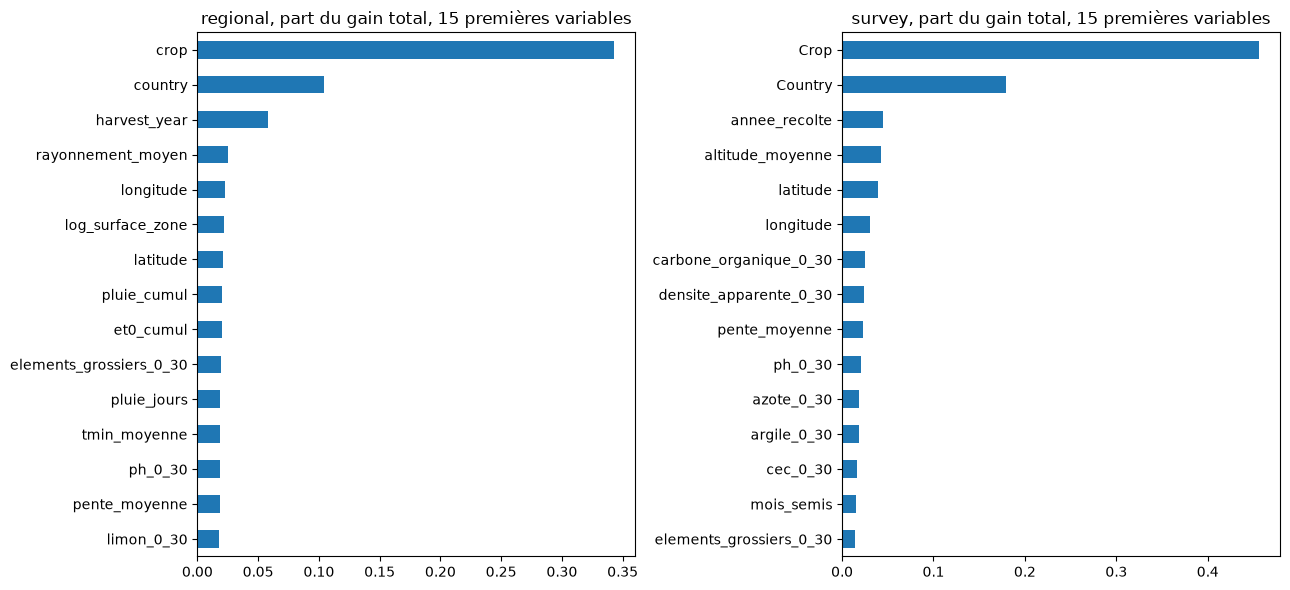

In [9]:
figure, axes = plt.subplots(1, 2, figsize=(13, 6))
for axe, jeu in zip(axes, ["regional", "survey"]):
    modele, description = charger_modele(jeu)
    importance = pd.Series(modele.feature_importance("gain"), index=modele.feature_name())
    importance = (importance / importance.sum()).sort_values()
    importance.tail(15).plot.barh(ax=axe)
    axe.set_title(f"{jeu}, part du gain total, 15 premières variables")
    print(jeu, ": part du gain des familles de variables")
    familles = {"climat": ["pluie", "bilan", "sequence", "et0", "degres", "tmax", "tmin", "dpv", "rayonnement"],
                "sols": ["_0_30"], "relief": ["altitude", "pente"], "calendrier": ["mois_", "duree"]}
    parts = {f: importance[[v for v in importance.index if any(m in v for m in motifs)]].sum() for f, motifs in familles.items()}
    parts["autres"] = 1 - sum(parts.values())
    print({f: round(p, 3) for f, p in parts.items()})
plt.tight_layout()
plt.show()

**Constat**

- Dans `regional`, les variables climatiques portent 20,5 % du gain, les sols 15,0 %, le relief 3,4 % et le calendrier 0,9 %. Le reste revient à la culture, au pays, à l'année, à la position, à la source et aux autres variables d'identité.
- Dans `survey`, les sols portent 16,5 % du gain et le relief 6,5 %.

**Analyse**

Le gain mesure l'usage d'une variable par les arbres et non sa contribution à la qualité des prédictions. Une variable corrélée à la position peut capter un gain que la position aurait capté à sa place. Les ablations de `10_modeling.ipynb` restent la mesure de référence de l'apport de chaque famille.

### 9. Synthèse

**Résultats**

| Ensemble | `regional`, modèle et référence | Compétence | `survey`, modèle et référence | Compétence |
|---|---|---:|---|---:|
| Test temporel | 0,310 et 0,398 | 22,3 % | 0,765 et 0,828 | 7,6 % |
| Test spatial | 0,321 et 0,389 | 17,4 % | 0,716 et 0,756 | 5,3 % |
| Test spatio-temporel | 0,334 et 0,404 | 17,2 % | 0,767 et 0,822 | 6,8 % |
| `cropcut`, grappes tenues à l'écart | | | 0,669 et 0,676 | 1,1 % |

**Décision**

Les deux modèles sont retenus. Ils battent la référence en validation croisée et sur chaque ensemble de test, conformément à la règle du protocole.

**Limites**

- Quinze rendements de tabac de `regional` sont des erreurs d'unité que le filtre des auteurs n'a pas détectées, et d'autres rendements de niébé, de sésame et de tabac restent suspects.
- Le modèle de `survey` reproduit le biais des rendements déclarés, qui dépassent les mesures par coupe.
- Le modèle de `regional` reste moins bon que la référence dans quelques pays peu représentés, comme le Mozambique sur les années futures.
- Le climat n'explique qu'une faible part de la variation annuelle, ce qui limite la capacité du modèle à anticiper une année exceptionnelle.